# 01 · Preprocessing and EDA
**Owner:** Chaitanya Sai Meka

Load the Corr2Cause splits, clean them, remove leakage, subsample train and explore the data.

In [ ]:
# ─── IMPORTS ─────
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import hf_hub_download

In [ ]:
# ─── LOAD DATA ─────
# download the three official splits (dev.csv is the validation split)
hf_hub_download("causal-nlp/corr2cause", "train.csv", repo_type="dataset", local_dir="../data/raw")
hf_hub_download("causal-nlp/corr2cause", "dev.csv", repo_type="dataset", local_dir="../data/raw")
hf_hub_download("causal-nlp/corr2cause", "test.csv", repo_type="dataset", local_dir="../data/raw")

train = pd.read_csv("../data/raw/train.csv")
validation = pd.read_csv("../data/raw/dev.csv")
test = pd.read_csv("../data/raw/test.csv")

In [ ]:
train.head()

,input,label,num_variables,template
0,Premise: Suppose there is a closed system of 4...,0,4,has_collider
1,Premise: Suppose there is a closed system of 4...,0,4,non-child descendant
2,Premise: Suppose there is a closed system of 4...,0,4,child
3,Premise: Suppose there is a closed system of 4...,0,4,non-parent ancestor
4,Premise: Suppose there is a closed system of 4...,1,4,parent


In [4]:
train.tail()

,input,label,num_variables,template
205729,Premise: Suppose there is a closed system of 6...,0,6,child
205730,Premise: Suppose there is a closed system of 6...,0,6,non-child descendant
205731,Premise: Suppose there is a closed system of 6...,0,6,parent
205732,Premise: Suppose there is a closed system of 6...,0,6,parent
205733,Premise: Suppose there is a closed system of 6...,0,6,non-child descendant


In [5]:
print(train.shape, validation.shape, test.shape)

(205734, 4) (1076, 4) (1162, 4)


In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 205734 entries, 0 to 205733
Data columns (total 4 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   input          205734 non-null  str  
 1   label          205734 non-null  int64
 2   num_variables  205734 non-null  int64
 3   template       205734 non-null  str  
dtypes: int64(2), str(2)
memory usage: 370.4 MB


In [7]:
# ─── STEP 1: MISSING VALUES AND DUPLICATES ─────
train.isnull().sum()

input            0
label            0
num_variables    0
template         0
dtype: int64

In [8]:
print(train.duplicated().sum(), validation.duplicated().sum(), test.duplicated().sum())

0 0 0


No missing values and no duplicates, so there is nothing to impute or drop.

In [9]:
# ─── STEP 2: COMBINE THE SPLITS ─────
# add a split column and put all three together, so we clean them once
train["split"] = "train"
validation["split"] = "validation"
test["split"] = "test"

data = pd.concat([train, validation, test], ignore_index=True)
data["split"].value_counts()

split
train         205734
test            1162
validation      1076
Name: count, dtype: int64

In [10]:
# ─── STEP 3: SPLIT INPUT INTO PREMISE AND HYPOTHESIS ─────
# every input should have exactly one "Hypothesis:"
(data["input"].str.count("Hypothesis:") != 1).sum()

np.int64(0)

In [11]:
data["input"] = data["input"].str.replace(r"\s+", " ", regex=True).str.strip()
data["premise"] = data["input"].str.split("Hypothesis:").str[0].str.replace("Premise:", "").str.strip()
data["hypothesis"] = data["input"].str.split("Hypothesis:").str[1].str.strip()
data["template"] = data["template"].str.strip()

data[["premise", "hypothesis", "label"]].head()

,premise,hypothesis,label
0,Suppose there is a closed system of 4 variable...,"There exists at least one collider (i.e., comm...",0
1,Suppose there is a closed system of 4 variable...,"C is a cause for B, but not a direct one.",0
2,Suppose there is a closed system of 4 variable...,C directly causes B.,0
3,Suppose there is a closed system of 4 variable...,B causes something else which causes C.,0
4,Suppose there is a closed system of 4 variable...,B directly causes C.,1


In [12]:
# num_variables should match the number written in the premise
stated = data["premise"].str.extract(r"closed system of (\d+) variables")[0].astype(int)
(stated != data["num_variables"]).sum()

np.int64(0)

In [13]:
# ─── STEP 4: PREMISE ID ─────
# the same premise is reused with many hypotheses, so rows with the same premise get the same id
data["premise_id"] = data["premise"].factorize()[0]
data["premise_id"].nunique()

2376

In [14]:
# ─── STEP 5: LEAKAGE CHECK ─────
# a premise that is in both train and test would already be seen by the model
train_ids = data[data["split"] == "train"]["premise_id"]
val_ids = data[data["split"] == "validation"]["premise_id"]
test_ids = data[data["split"] == "test"]["premise_id"]

print("train & validation:", train_ids[train_ids.isin(val_ids)].nunique())
print("train & test:      ", train_ids[train_ids.isin(test_ids)].nunique())
print("validation & test: ", val_ids[val_ids.isin(test_ids)].nunique())

train & validation: 2
train & test:       0
validation & test:  3


In [15]:
# keep test as it is, remove the shared premises from validation and train
data = data[~((data["split"] == "validation") & data["premise_id"].isin(test_ids))]
val_ids = data[data["split"] == "validation"]["premise_id"]
data = data[~((data["split"] == "train") & (data["premise_id"].isin(val_ids) | data["premise_id"].isin(test_ids)))]

train_ids = data[data["split"] == "train"]["premise_id"]
print("train & validation:", train_ids[train_ids.isin(val_ids)].nunique())
print("train & test:      ", train_ids[train_ids.isin(test_ids)].nunique())
print("validation & test: ", val_ids[val_ids.isin(test_ids)].nunique())

train & validation: 0
train & test:       0
validation & test:  0


In [16]:
# ─── STEP 6: SUBSAMPLE TRAIN ─────
# train is too big, so we take 400 whole premises (with all their hypotheses)
columns = ["premise_id", "split", "premise", "hypothesis", "label", "num_variables", "template"]
train = data[data["split"] == "train"][columns]
validation = data[data["split"] == "validation"][columns]
test = data[data["split"] == "test"][columns]

chosen = train["premise_id"].drop_duplicates().sample(n=400, random_state=42)
full_train = train
train = train[train["premise_id"].isin(chosen)]

print(train.shape, validation.shape, test.shape)

(35340, 7) (1026, 7) (1162, 7)


In [17]:
# the subsample should have the same share of label 1 as the full train
print(full_train["label"].mean(), train["label"].mean())

0.18490366004299066 0.18491794001131862


In [18]:
# ─── STEP 7: EDA ─────
all_splits = pd.concat([train, validation, test])
premises = all_splits.drop_duplicates("premise_id")

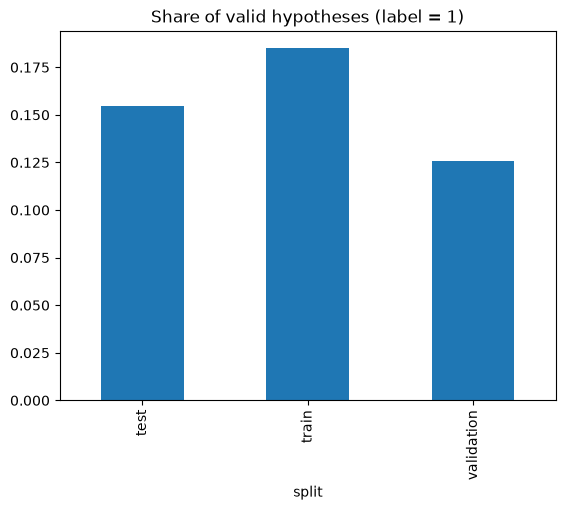

In [19]:
# label balance
all_splits.groupby("split")["label"].mean().plot(kind="bar", title="Share of valid hypotheses (label = 1)")
plt.show()

Only about 1 in 5 hypotheses is valid, so accuracy is misleading. We use precision, recall, F1 and class weights.

In [20]:
# hypothesis types
train["template"].value_counts()

template
non-child descendant    5931
child                   5890
parent                  5890
has_confounder          5890
has_collider            5890
non-parent ancestor     5849
Name: count, dtype: int64

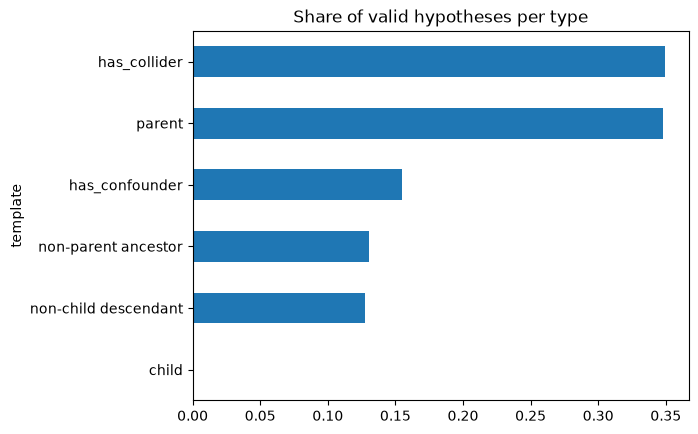

In [21]:
train.groupby("template")["label"].mean().sort_values().plot(kind="barh", title="Share of valid hypotheses per type")
plt.show()

"child" is never valid, and its text is the same as "parent". So `template` would leak the label and
**we never use it as a feature**, only for error analysis.

In [22]:
# number of variables per premise
pd.crosstab(premises["split"], premises["num_variables"])

num_variables,2,3,4,5,6
split,,,,,
test,1,3,2,9,6
train,0,0,0,22,378
validation,1,2,2,8,6


Train only has 5–6 variables, while validation and test also have 2–4.

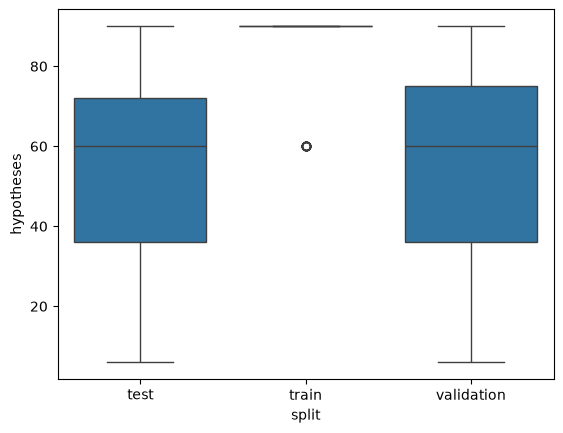

In [23]:
# hypotheses per premise
repeats = all_splits.groupby(["split", "premise_id"]).size().reset_index(name="hypotheses")
sns.boxplot(data=repeats, x="split", y="hypotheses")
plt.show()

One premise can have up to 90 hypotheses, so we always group by premise (splits, CV, bootstrap).

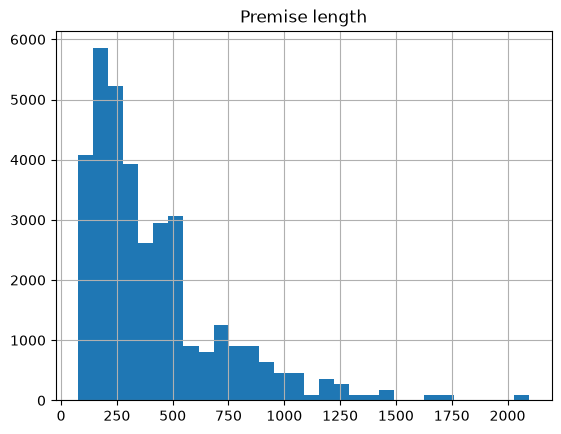

In [24]:
# text lengths in words
train["premise"].str.split().str.len().hist(bins=30)
plt.title("Premise length")
plt.show()

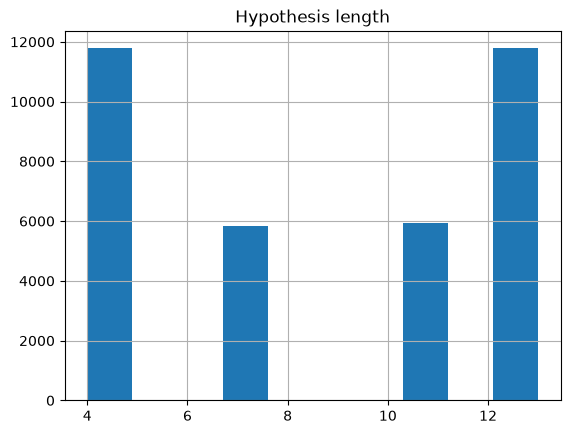

In [25]:
train["hypothesis"].str.split().str.len().hist(bins=10)
plt.title("Hypothesis length")
plt.show()

In [26]:
# ─── STEP 8: SAVE AS CSV ─────
os.makedirs("../data/processed", exist_ok=True)
train.to_csv("../data/processed/train.csv", index=False)
validation.to_csv("../data/processed/validation.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)